# Car Price Prediction Using Machine Learning

## Internship: Oasis Infobyte (OIBSIP)
### Track: Data Science
### Task: Task 3 - Car Price Prediction

**Objective:** To predict the selling price of a used car using machine learning algorithms.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("dataset/car_data.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Records: 2

Statistical Summary:


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [5]:
df = df.drop_duplicates()

print("Data Cleaning Completed!")
print("Updated Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Data Cleaning Completed!
Updated Dataset Shape: (299, 9)

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


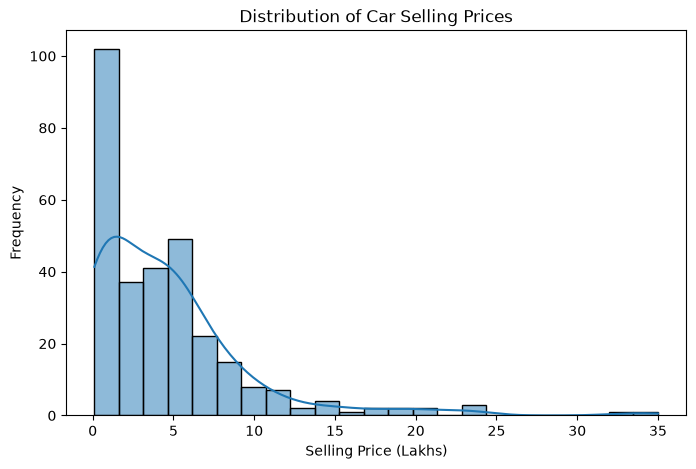

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

In [7]:
# Create Car Age feature
df["Car_Age"] = 2026 - df["Year"]

# Select input features
X = df[
    [
        "Present_Price",
        "Kms_Driven",
        "Fuel_Type",
        "Seller_Type",
        "Transmission",
        "Owner",
        "Car_Age"
    ]
]

# Select target variable
y = df["Selling_Price"]

print("Features and Target Selected Successfully!")
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features and Target Selected Successfully!
Input Features Shape: (299, 7)
Target Shape: (299,)


In [8]:
# Identify categorical and numerical columns
categorical_features = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

numerical_features = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Car_Age"
]

# Convert categorical values into numerical values
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 239
Testing Records: 60


In [9]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [10]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [11]:
models = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 2))


Model: Linear Regression
MAE: 1.47
RMSE: 2.52
R2 Score: 0.75

Model: Random Forest
MAE: 1.56
RMSE: 3.82
R2 Score: 0.44


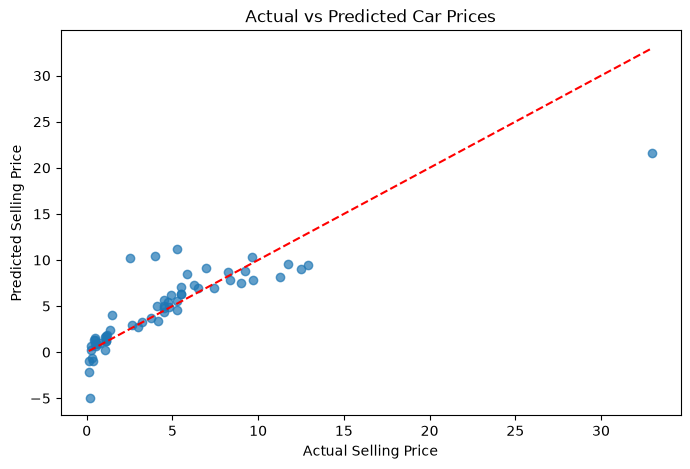

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, linear_predictions, alpha=0.7)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.472892,2.524035,0.752815
1,Random Forest,1.563197,3.815155,0.435252


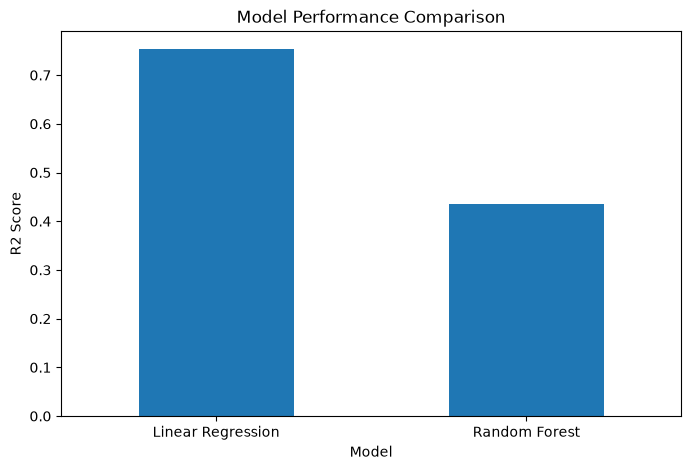

In [13]:
results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df)

results_df.set_index("Model")[["R2 Score"]].plot(
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.show()

In [14]:
prediction_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Linear Regression Prediction": linear_predictions,
    "Random Forest Prediction": rf_predictions
})

prediction_results.to_csv(
    "output/notebook_prediction_results.csv",
    index=False
)

print("Prediction Results Saved Successfully!")

Prediction Results Saved Successfully!


In [15]:
new_car = pd.DataFrame([{
    "Present_Price": 5.59,
    "Kms_Driven": 27000,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0,
    "Car_Age": 8
}])

predicted_price = linear_model.predict(new_car)

print("Predicted Car Selling Price: ₹", round(predicted_price[0], 2), "Lakhs")

Predicted Car Selling Price: ₹ 5.26 Lakhs


## Conclusion

In this project, a machine learning model was developed to predict the selling prices of used cars.

The dataset was analyzed and cleaned before training the models. Two machine learning algorithms were implemented:

1. Linear Regression
2. Random Forest Regressor

Both models were evaluated using MAE, RMSE, and R2 Score.

The model with better performance was selected for predicting car prices.

This project demonstrates how machine learning can help estimate used car prices based on vehicle features such as present price, kilometers driven, fuel type, transmission, and car age.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Project Outcome

The project successfully demonstrates the use of regression algorithms for used car price prediction.